# 02 · Référentiel de blocs et enrichissement sémantique (P2)

**Problème.** Le sujet suggère la structure `BookID | Genre | Title | Author | Synopsis | Themes | Style | Keywords`. Le dataset Book Depository n'a **ni thèmes, ni style, ni mots-clés**, et ses ~1 000 catégories sont bruitées. On les **dérive par analyse sémantique** (embeddings SBERT) au lieu de les saisir à la main.

**Plan :** 1) taxonomie `blocks.json` → 2) catégories → genres → 3) zero-shot thèmes/style/atmosphère → 4) mots-clés → 5) validation → 6) export.

In [1]:
# --- Imports et chemins (le notebook s'exécute depuis notebooks/, on remonte à la racine du repo)
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import enrichment as en

FIG = ROOT / "docs" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
df = pd.read_parquet(ROOT / "data/processed/books_clean.parquet")   # catalogue de P1 (12 000 livres)
print(df.shape)

Matplotlib is building the font cache; this may take a moment.


(12000, 24)


## 1. La taxonomie (`blocks.json`)
4 blocs (Genre, Thèmes, Style, Atmosphère), chacun avec des labels **et une phrase descriptive par label**. C'est la *phrase* qu'on encode : « boy wizard school » est ainsi proche de *Fantasy* sans que le mot apparaisse. La taxonomie s'inspire des grandes familles de genres de l'édition (BISAC / rayons de librairie) et de thèmes classiques de l'analyse littéraire. Les 6 labels d'**époque** (Ancient world … Future) alimentent aussi la question Q7 du questionnaire.

In [2]:
blocks = en.load_blocks()                       # valide aussi que chaque label a une vraie phrase
pd.DataFrame({b: [len(v)] for b, v in blocks.items()}, index=["nb de labels"])

,Genre,Themes,Style,Atmosphere
nb de labels,21,20,10,15


In [3]:
# Exemple : un label et sa phrase descriptive (c'est elle qui est encodée)
for b in en.BLOCK_NAMES:
    l = next(iter(blocks[b])); print(f"{b:11s} | {l:25s} | {blocks[b][l]}")

Genre       | Fantasy                   | Fantasy fiction with magic, wizards, dragons, mythical creatures, imaginary worlds and epic quests
Themes      | Identity & self-discovery | A story about self-discovery, identity and finding out who you really are
Style       | Fast-paced page-turner    | A gripping, fast-paced, suspenseful plot with short chapters that is hard to put down
Atmosphere  | Ancient world             | Set in the ancient world, in antiquity, with gods, early empires, Greece, Rome or Egypt


## 2. Embeddings (modèle `all-MiniLM-L6-v2`, comme P3)
Vecteurs **L2-normalisés** : le produit scalaire est alors égal au cosinus. Les embeddings sont mis en cache sur disque (relancer est instantané). Quand `EmbeddingEngine` (P3) sera prêt, il suffit de le passer à la place de `SbertEncoder` (même méthode `encode`).

In [4]:
encoder = en.SbertEncoder()                                                   # chargement paresseux
book_emb = en.encode_cached(encoder, df["embed_text"].fillna("").tolist(),
                            df["book_id"].astype(str).tolist(), "p2_all-MiniLM-L6-v2_clean_books")
enc_blocks = en.encode_blocks(encoder, blocks)
print(book_emb.shape, {b: m.shape for b, (_, m) in enc_blocks.items()})

W1121 22:30:04.156000 26636 .venv311/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

(12000, 384) {'Genre': (21, 384), 'Themes': (20, 384), 'Style': (10, 384), 'Atmosphere': (15, 384)}


## 3. Catégories Book Depository → Genres
Les catégories sont nombreuses et bruitées (« Fiction », « Teaching Resources »…). Stratégie en 2 temps : des **règles mots-clés** pour les cas évidents (« Fantasy Books » → Fantasy) puis, pour le reste, le **genre le plus proche par embeddings** (accepté seulement si cosinus ≥ 0,30, sinon la catégorie est jugée trop générique). La table est exportée dans `data/reference/category_genre_map.csv` avec une colonne **`genre_manual`** : on y relit à la main les 100 catégories les plus fréquentes ; elle est conservée à chaque régénération.

In [5]:
counts = en.category_counts(df)
# On passe le fichier existant pour CONSERVER la colonne genre_manual (corrections faites à la main)
existing = pd.read_csv(en.CATEGORY_MAP_PATH, keep_default_na=False) if en.CATEGORY_MAP_PATH.exists() else None
cat_map = en.build_category_map(counts, encoder, blocks, existing)
cat_map.to_csv(en.CATEGORY_MAP_PATH, index=False)
cat_map.head(30)[["category", "n_books", "rule_genres", "emb_genre", "emb_sim", "genre_auto", "genre_manual"]]

,category,n_books,rule_genres,emb_genre,emb_sim,genre_auto,genre_manual
0,Contemporary Fiction,3538,Literary Fiction,Literary Fiction,0.657,Literary Fiction,
1,Thriller Books,1102,Thriller & Suspense,Thriller & Suspense,0.603,Thriller & Suspense,
2,Thrillers,1102,Thriller & Suspense,Thriller & Suspense,0.521,Thriller & Suspense,
3,Adult & Contemporary Romance,1073,Romance,Young Adult,0.602,Romance,
4,Romance,1067,Romance,Romance,0.553,Romance,
5,Romance Books,1067,Romance,Romance,0.678,Romance,
6,Crime,971,,Mystery & Detective,0.454,Mystery & Detective,
7,Crime Fiction,971,Mystery & Detective,Mystery & Detective,0.575,Mystery & Detective,
8,Children's Fiction,906,Children's,Young Adult,0.610,Children's,
9,Classic Books & Novels,855,Classics,Classics,0.710,Classics,


In [6]:
# Part des catégories (et des occurrences) résolues par règle / par embeddings / non résolues
has_rule = cat_map["rule_genres"] != ""
has_auto = cat_map["genre_auto"] != ""
print(f"règles: {has_rule.mean():.0%} | embeddings seuls: {(~has_rule & has_auto).mean():.0%} | non résolues: {(~has_auto).mean():.0%} des catégories")
w = cat_map["n_books"]
print(f"pondéré par les occurrences : résolues {w[has_auto].sum() / w.sum():.0%}")

règles: 39% | embeddings seuls: 26% | non résolues: 36% des catégories
pondéré par les occurrences : résolues 92%


In [7]:
genre_labels, genre_emb = enc_blocks["Genre"]
genres, g_stats = en.assign_genres(df, book_emb, genre_labels, genre_emb, cat_map)
print(g_stats)
df.assign(genres=genres)[["title", "categories", "genres"]].sample(8, random_state=1)

{'n_books': 12000, 'n_fallback_embedding': 7, 'pct_fallback': 0.06}


,title,categories,genres
7163,Buddha : A Story of Enlightenment,[Buddhist Books],"[Biography & Memoir, Philosophy & Religion]"
10385,"Alvin Ho : Allergic to Girls, School, and Othe...","[Children's Fiction, Children's General Story ...","[Children's, Horror, Humour]"
1902,Salt,"[General & World History, Social & Cultural Hi...","[History, Cooking & Lifestyle, Science & Nature]"
3397,The Fountains of Silence,"[Children's General Story Books, Romance Books...","[Young Adult, Literary Fiction, Romance]"
11695,Zero Day : A Novel,"[Contemporary Fiction, Thriller Books, Thrille...","[Thriller & Suspense, Science Fiction, Literar..."
6443,Elixir,"[Children's Fiction, Mystery Books for Kids, F...","[Young Adult, Literary Fiction, Romance]"
10786,"Triplanetary by E. E. 'Doc' Smith, Science Fic...","[Adventure Books, Science Fiction, Space Opera]","[Science Fiction, Classics, Thriller & Suspense]"
9406,Dragonquest : A Novel,"[Contemporary Fiction, Fantasy, Fantasy Books,...","[Fantasy, Children's, Literary Fiction]"


## 4. Zero-shot par embeddings : Thèmes, Style, Atmosphère
Pour chaque livre : cosinus entre l'embedding de sa description et celui de la phrase de chaque label. Deux précautions :

* **Normalisation par label** : certaines phrases sont proches de *tous* les livres. On soustrait donc la moyenne du label sur le catalogue (« ce livre est-il plus proche de ce label que le livre moyen ? »), avec une échelle commune au bloc. Un écart-type par label gonflait les labels peu dispersés et donnait des labels aberrants.
* **Seuil calibré** (`z_min`) et au moins 1 label garanti. Atmosphère = **1 époque + 1 ambiance**.

In [8]:
# Calibration du seuil : nb moyen de labels gardés selon z_min (on vise ~ top_k pour Thèmes, sans labels « forcés » partout)
for block in ["Themes", "Style", "Atmosphere"]:
    labels, emb = enc_blocks[block]
    print(block); display(en.threshold_report(en.score_block(book_emb, emb), labels, block))

Themes


,z_min,mean_labels_kept,pct_books_no_label_above_threshold
0,0.0,2.79,3.2
1,0.5,2.45,10.9
2,1.0,1.95,26.1
3,1.5,1.47,47.8
4,2.0,1.18,69.2


Style


,z_min,mean_labels_kept,pct_books_no_label_above_threshold
0,0.0,1.82,9.4
1,0.5,1.61,22.4
2,1.0,1.36,44.1
3,1.5,1.15,67.1
4,2.0,1.05,84.6


Atmosphere


,z_min,mean_labels_kept,pct_books_no_label_above_threshold
0,0.0,1.85,1.6
1,0.5,1.61,7.8
2,1.0,1.32,23.5
3,1.5,1.12,47.3
4,2.0,1.03,70.5


In [9]:
assigned, sims_by_block = {}, {"Genre": (genre_labels, en.score_block(book_emb, genre_emb))}
for block in ["Themes", "Style", "Atmosphere"]:
    labels, emb = enc_blocks[block]
    assigned[block], sims = en.assign_labels(book_emb, labels, emb, block, z_min=en.Z_MIN)
    sims_by_block[block] = (labels, sims)
df.assign(themes=assigned["Themes"], styles=assigned["Style"], atmospheres=assigned["Atmosphere"])[
    ["title", "themes", "styles", "atmospheres"]].sample(8, random_state=1)

,title,themes,styles,atmospheres
7163,Buddha : A Story of Enlightenment,"[Faith & spirituality, Nature & environment, A...","[Slow and contemplative, Dense literary prose]","[Cozy & heartwarming, Contemporary]"
10385,"Alvin Ho : Allergic to Girls, School, and Othe...","[Madness & the mind, Technology & humanity]",[Epic & multi-perspective],[Dark & unsettling]
1902,Salt,"[Power & politics, Freedom & oppression, Faith...",[Dense literary prose],[Ancient world]
3397,The Fountains of Silence,"[Power & politics, Faith & spirituality, Madne...","[Lyrical & poetic, Plot-driven & twisty]",[Melancholic]
11695,Zero Day : A Novel,[Survival],[Simple & accessible],[20th century]
6443,Elixir,"[Family relationships, Love & heartbreak, Iden...",[Character-driven],[Melancholic]
10786,"Triplanetary by E. E. 'Doc' Smith, Science Fic...","[Nature & environment, Adventure & exploration...","[Simple & accessible, Dense literary prose]",[Whimsical & magical]
9406,Dragonquest : A Novel,[Power & politics],[Slow and contemplative],[Medieval]


**Optionnel (discussion qualité/temps)** : comparer sur ~200 livres avec un vrai zero-shot NLI (`facebook/bart-large-mnli`). Il est nettement plus lent (une passe du modèle par couple livre × label) ; nos embeddings donnent un classement de tout le catalogue en quelques secondes.

In [10]:
# (Optionnel) zero-shot NLI sur 200 livres : plusieurs minutes sur CPU, à lancer si on a le temps.
RUN_NLI = False
if RUN_NLI:
    import time
    from transformers import pipeline
    nli = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")
    sub = df.sample(200, random_state=0)
    theme_labels = list(blocks["Themes"])
    t0 = time.time()
    nli_top = [nli(t[:600], theme_labels, multi_label=True)["labels"][:3] for t in sub["description"]]
    print(f"NLI: {time.time() - t0:.0f}s pour 200 livres")

## 5. Mots-clés (principe KeyBERT)
On garde l'algorithme de KeyBERT (cosinus candidat↔document + **MMR**, diversité 0,5, 1-2 mots) mais on **pré-filtre les candidats par TF-IDF** : KeyBERT standard encoderait tout le vocabulaire de la collection (centaines de milliers de phrases), trop lent sur CPU. Résultat identique en principe, en quelques minutes.

In [11]:
keywords = en.extract_keywords(df, book_emb, encoder)
df.assign(keywords=keywords)[["title", "keywords"]].sample(8, random_state=1)

,title,keywords
7163,Buddha : A Story of Enlightenment,"[enlightenment, buddha, depths despair, human ..."
10385,"Alvin Ho : Allergic to Girls, School, and Othe...","[alvin, unforgettable character, diary wimpy, ..."
1902,Salt,"[substance plato, salt, rule india, homer call..."
3397,The Fountains of Silence,"[salt sea, franco, history darkest, silence, f..."
11695,Zero Day : A Novel,"[chernobyl, airliner, realizes isn, aiken, sud..."
6443,Elixir,"[father disappearance, dangerous love, future-..."
10786,"Triplanetary by E. E. 'Doc' Smith, Science Fic...","[published amazing, columns, narrative power, ..."
9406,Dragonquest : A Novel,"[kale, meech dragon, wizard risto, gaining pow..."


In [12]:
# (Optionnel) comparaison avec la vraie bibliothèque KeyBERT sur 5 livres
sub = df.sample(5, random_state=2)
for t, mine in zip(sub["title"], [keywords[i] for i in sub.index]):
    print(t[:40], "| à nous:", mine)
# lib = [en.extract_keywords_keybert_lib([d]) for d in sub["description"]]   # décommenter si keybert est installé

The Favored Child | à nous: ['wideacre estate', 'beatrice lacey', 'favored', 'children raised', 'royal fiction']
Hidden Messages in Water | à nous: ['water', 'negative thoughts', 'words shows', 'brilliant complex', 'snowflake']
The Haunting of Maddy Clare | à nous: ['maddy', 'ghost real', 'alistair', 'ryder', 'committed suicide']
The Potter's Field | à nous: ['cadfael', 'mysteries surrounding', 'benedictines', 'field', 'forced abandon']
Protector | à nous: ['brennan', 'asteroid belt', 'pak', 'mission save', 'fiercely independent']


## 6. Assemblage et export (contrat `books_enriched.parquet`)

In [13]:
# Enrichissement de BASE (v1) recalculé en mémoire, pour illustrer le pipeline.
# ATTENTION : on ne l'écrit PAS sur disque. Le fichier final books_enriched.parquet est produit par
#   python -m scripts.run_enrichment   (v2 des thèmes intégrée à enrich_catalogue)
# et l'écraser ici supprimerait l'amélioration des thèmes.
enriched_v1, report = en.enrich_catalogue(df, encoder, blocks, cat_map, book_emb)
print(report)

# Pour les visualisations et l'évaluation ci-dessous, on utilise le fichier FINAL du repo.
enriched = pd.read_parquet(ROOT / "data/processed/books_enriched.parquet")
print("fichier final :", enriched.shape)

[1/5] Encodage des livres et des phrases de labels
[2/5] Genres (catégories -> genres, repli embeddings)


[3/5] Zero-shot Themes / Style / Atmosphere


[4/5] Mots-clés


[5/5] Assemblage


{'n_books': 12000, 'z_min': 1.0, 'genres': {'n_books': 12000, 'n_fallback_embedding': 7, 'pct_fallback': 0.06}, 'mean_labels': {'genres': 2.42, 'themes': 1.95, 'styles': 1.36, 'atmospheres': 1.32, 'keywords': 5.0}}
fichier final : (12000, 30)


## 7. Visualisations (rapport)
Répartition des genres et des thèmes, puis **heatmap genre × thème** : elle illustre les « relations entre catégories » (ex. *Mystery* ↔ *Crime & justice*).

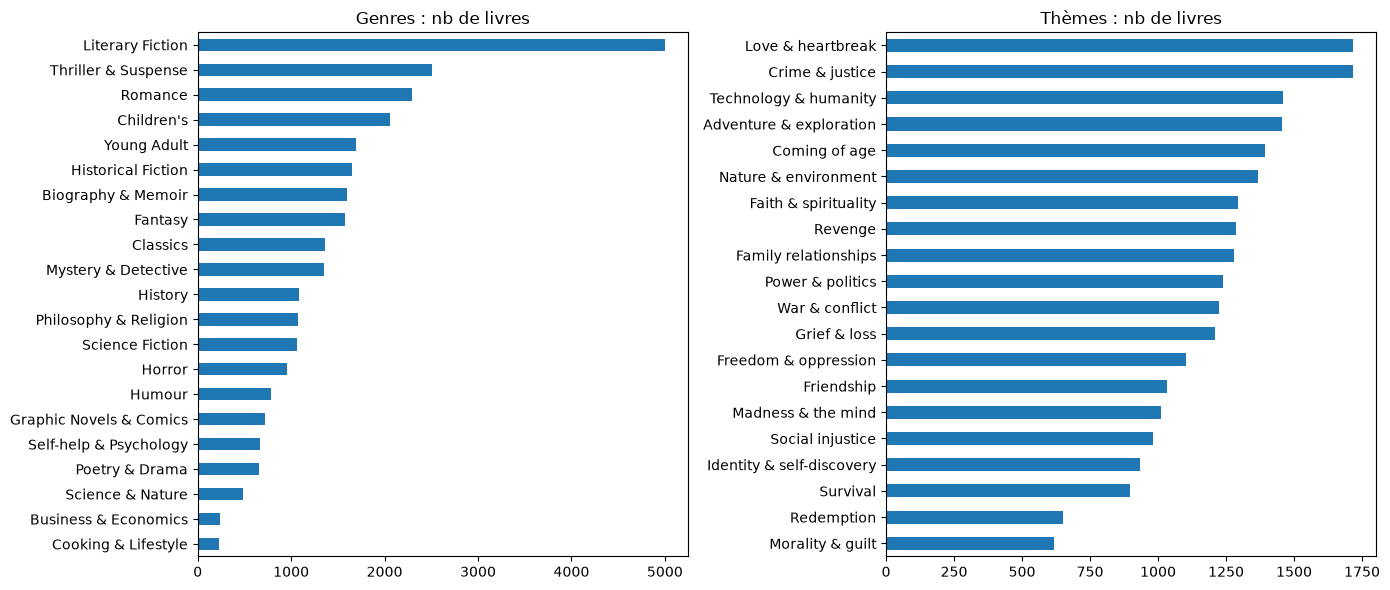

In [14]:
from collections import Counter
fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, (col, title) in zip(ax, [("genres", "Genres"), ("themes", "Thèmes")]):
    c = Counter(l for ls in enriched[col] for l in ls); s = pd.Series(c).sort_values()
    s.plot.barh(ax=a); a.set_title(f"{title} : nb de livres"); 
plt.tight_layout(); plt.savefig(FIG / "02_genres_themes_distribution.png", dpi=150); plt.show()

/var/folders/vy/kmt_4gwd0tgg1274dmrdyy680000gn/T/ipykernel_26636/234096688.py:7: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  Mn = M.div(M.sum(1).replace(0, 1), axis=0)             # normalisé par genre : « profil thématique » de chaque genre


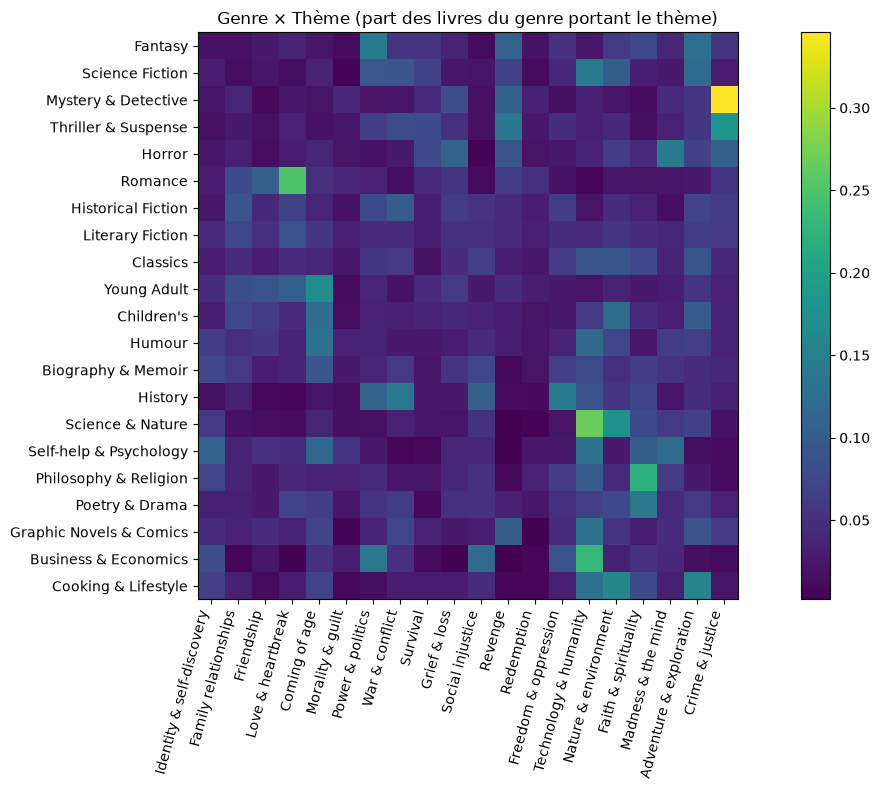

In [15]:
# Co-occurrence genre x thème (nb de livres portant les deux labels)
G, T = list(blocks["Genre"]), list(blocks["Themes"])
M = pd.DataFrame(0, index=G, columns=T)
for gs, ts in zip(enriched["genres"], enriched["themes"]):
    for g in gs:
        for t in ts: M.loc[g, t] += 1
Mn = M.div(M.sum(1).replace(0, 1), axis=0)             # normalisé par genre : « profil thématique » de chaque genre
fig, ax = plt.subplots(figsize=(13, 8)); im = ax.imshow(Mn.values, cmap="viridis")
ax.set_xticks(range(len(T)), T, rotation=75, ha="right"); ax.set_yticks(range(len(G)), G)
ax.set_title("Genre × Thème (part des livres du genre portant le thème)"); plt.colorbar(im)
plt.tight_layout(); plt.savefig(FIG / "02_heatmap_genre_theme.png", dpi=150); plt.show()

## 8. Validation sur 60 livres annotés
1. `python -m scripts.run_enrichment --annotation-sheet` écrit `data/reference/gold_60_to_annotate.csv` (**sans** les prédictions, pour ne pas biaiser).
2. L'annotation (`gold_genres`, `gold_themes`, labels de `blocks.json` séparés par `|`) a été **proposée par Claude** à partir des descriptions, **sans accès aux prédictions du modèle**, puis **relue et corrigée par l'étudiante** (fichier `data/reference/gold_60_clean.csv`).
3. On mesure precision@k, recall, « le 1er label est dans l'annotation » et « au moins un label correct ». Le détail est dans `data/reference/gold_eval_report.csv` (script `scripts/evaluate_enrichment.py`).

In [16]:
gold_path = next((p for p in [ROOT / "data/reference/gold_60_clean.csv", ROOT / "data/reference/gold_60.csv"] if p.exists()), None)
if gold_path is not None:
    res = en.evaluate_against_gold(enriched, gold_path); display(pd.DataFrame(res).T)
else:
    print("fichier annoté absent : voir la procédure ci-dessus.")

,n,precision@k,recall,top1_in_gold,at_least_one_match
genres,60.0,0.633,0.800,0.733,0.983
themes,60.0,0.497,0.386,0.550,0.700


In [17]:
# 10 bons exemples + 5 erreurs : à choisir et commenter à la main pour le rapport
view = enriched[["title", "description", "genres", "themes", "styles", "atmospheres", "keywords"]].sample(15, random_state=7)
view.assign(description=view["description"].str.slice(0, 160))

,title,description,genres,themes,styles,atmospheres,keywords
9063,The Winter Soldier,"Vienna, 1914. Lucius is a twenty-two-year-old ...","[Historical Fiction, Thriller & Suspense, Lite...","[War & conflict, Survival]",[Fast-paced page-turner],[20th century],"[winter soldier, lucius, vienna, finds freezin..."
7451,Chronicles of Amber,"Amber is the one real world, casting infinite ...","[Fantasy, Science Fiction]",[Power & politics],[Epic & multi-perspective],"[Ancient world, Dark & unsettling]","[amber, royal family, reflections, oberon, app..."
8370,KAREN'S WITCH #1,"Karen Brewer lives next door to Mrs. Porter, w...","[Children's, Horror, Graphic Novels & Comics]",[Crime & justice],[Plot-driven & twisty],"[18th-19th century, Dark & unsettling]","[witch named, karen, black cat, lives door, po..."
1857,Vanish,Jane Rizzoli and Maura Isles--the inspiration ...,"[Thriller & Suspense, Mystery & Detective]","[Crime & justice, Revenge, Grief & loss]","[Plot-driven & twisty, Fast-paced page-turner]",[Urban & gritty],"[jane rizzoli, hostage crisis, just corpse, ma..."
247,Speak,The first ten lies they tell you in high schoo...,"[Literary Fiction, Young Adult, Children's]","[Coming of age, Redemption, Madness & the mind]","[Dark & gritty voice, Slow and contemplative]",[20th century],"[melinda, delivers blow, high school, solace w..."
2105,Motorcycle Man,Get ready to ride... Tyra Masters has had enou...,"[Romance, Thriller & Suspense, Literary Fiction]",[Revenge],[Fast-paced page-turner],[Tense & suspenseful],"[hot sex, muscled biker, finds breaking, man w..."
3433,Her Royal Spyness,THE FIRST ROYAL SPYNESS MYSTERY! The New York ...,[Mystery & Detective],[Crime & justice],[Simple & accessible],[18th-19th century],"[royal spyness, eugenie, feisty heroine, londo..."
4036,A Shameful Life : (Ningen Shikkaku),Osamu Dazai is one of the most famous--and inf...,[Literary Fiction],"[Grief & loss, Morality & guilt, Redemption]","[Lyrical & poetic, Slow and contemplative]",[Romantic],"[suicide attempts, century japan, dark tale, p..."
7200,A Dog's Way Home,A Dog's Way Home is now a feature film from So...,"[Children's, Thriller & Suspense, Literary Fic...",[Nature & environment],[Simple & accessible],[Cozy & heartwarming],"[dog journey, way home, home dog, jonah hauer-..."
5988,Peach Cobbler Murder,Joanne Fluke's Peach Cobbler Murder is repacka...,[Mystery & Detective],[Crime & justice],[Plot-driven & twisty],[Small town],"[peach, recipes try, hannah, bakery, investiga..."


## Conclusion
Le catalogue est enrichi de `genres`, `themes`, `styles`, `atmospheres`, `keywords` et `label_scores` **sans annotation manuelle à grande échelle** : tout vient de la sémantique des descriptions. Les thèmes ont ensuite été affinés (v2) sur les 60 livres annotés : voir `scripts/tune_theme_phrases.py` et `data/reference/theme_variants.json`.

Limites : les descriptions sont des textes marketing (biais de ton), la normalisation suppose une distribution raisonnablement régulière, et la troncature à 256 tokens de MiniLM ignore la fin des longues descriptions. Pistes : MPNet, zero-shot NLI sur les cas ambigus, correction manuelle ciblée.
